# Bloc 3 – Détection de fraude - Partie 1 : EDA et modèle de base

**Objectif de ce notebook** : entraîner un premier modèle simple (régression logistique) qui prédit si un paiement est frauduleux.

Plan :
1. Chargement des données
2. EDA
3. Préparation des variables
4. Train / validation / test
5. Entraînement du modèle
6. Évaluation sur le test
7. Vérification sur une transaction donnée par l'API

In [113]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

RANDOM_STATE = 0

## 1. Chargement des données

In [114]:
# lecture directe du csv - dans les livrables, mettre le lien vers le S3 de jedha
df = pd.read_csv("fraudTest.csv", index_col=0)
print(df.shape)
df.head()

(555719, 22)


,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,2020-06-21 12:14:25,2291163933867244,fraud_Kirlin and Sons,personal_care,2.86,Jeff,Elliott,M,351 Darlene Green,Columbia,...,33.9659,-80.9355,333497,Mechanical engineer,1968-03-19,2da90c7d74bd46a0caf3777415b3ebd3,1371816865,33.986391,-81.200714,0
1,2020-06-21 12:14:33,3573030041201292,fraud_Sporer-Keebler,personal_care,29.84,Joanne,Williams,F,3638 Marsh Union,Altonah,...,40.3207,-110.4360,302,"Sales professional, IT",1990-01-17,324cc204407e99f51b0d6ca0055005e7,1371816873,39.450498,-109.960431,0
2,2020-06-21 12:14:53,3598215285024754,"fraud_Swaniawski, Nitzsche and Welch",health_fitness,41.28,Ashley,Lopez,F,9333 Valentine Point,Bellmore,...,40.6729,-73.5365,34496,"Librarian, public",1970-10-21,c81755dbbbea9d5c77f094348a7579be,1371816893,40.495810,-74.196111,0
3,2020-06-21 12:15:15,3591919803438423,fraud_Haley Group,misc_pos,60.05,Brian,Williams,M,32941 Krystal Mill Apt. 552,Titusville,...,28.5697,-80.8191,54767,Set designer,1987-07-25,2159175b9efe66dc301f149d3d5abf8c,1371816915,28.812398,-80.883061,0
4,2020-06-21 12:15:17,3526826139003047,fraud_Johnston-Casper,travel,3.19,Nathan,Massey,M,5783 Evan Roads Apt. 465,Falmouth,...,44.2529,-85.0170,1126,Furniture designer,1955-07-06,57ff021bd3f328f8738bb535c302a31b,1371816917,44.959148,-85.884734,0


## 2. EDA

In [115]:
# Valeurs manquantes et doublons
print("Valeurs manquantes au total :", df.isna().sum().sum())
print("Doublons (trans_num) :", df["trans_num"].duplicated().sum())
df.dtypes

Valeurs manquantes au total : 0
Doublons (trans_num) : 0


trans_date_trans_time        str
cc_num                     int64
merchant                     str
category                     str
amt                      float64
first                        str
last                         str
gender                       str
street                       str
city                         str
state                        str
zip                        int64
lat                      float64
long                     float64
city_pop                   int64
job                          str
dob                          str
trans_num                    str
unix_time                  int64
merch_lat                float64
merch_long               float64
is_fraud                   int64
dtype: object

In [116]:
# equilibre des classes
counts = df["is_fraud"].value_counts()
print(counts)
print()
print(f"part de fraudes : {(df["is_fraud"].mean()*100).round(3)} %")

is_fraud
0    553574
1      2145
Name: count, dtype: int64

part de fraudes : 0.386 %


## variables numériques

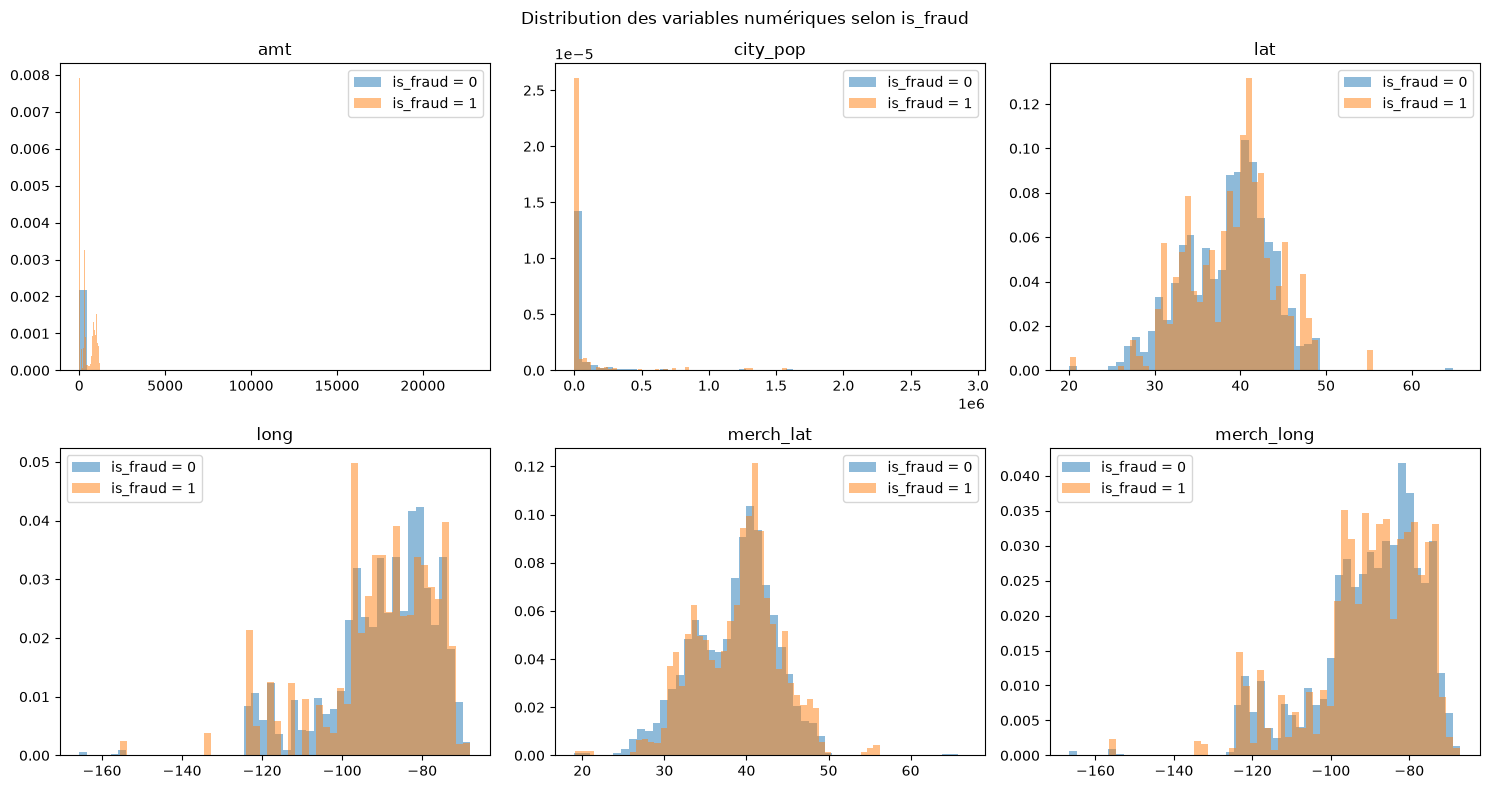

In [117]:
num_cols = ["amt", "city_pop", "lat", "long", "merch_lat", "merch_long"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()
for ax, col in zip(axes, num_cols):
    for label, groupe in df.groupby("is_fraud"):
        ax.hist(groupe[col], bins=50, density=True, alpha=0.5, label=f"is_fraud = {label}")
    ax.set_title(col)
    ax.legend()
fig.suptitle("Distribution des variables numériques selon is_fraud")
plt.tight_layout()
plt.show()

In [118]:
# Montants
df.groupby("is_fraud")["amt"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
0,553574.0,67.61,152.47,1.00,9.60,47.15,82.62,22768.11
1,2145.0,528.36,392.75,1.78,214.51,371.94,907.77,1320.92


Les fraudes ont un montant médian plus élevé que les paiements réguliers (372 vs 47).
Mais le montant maximal des paiements réguliers est très haut. On utilise une échelle logarithmique pour la visualisation

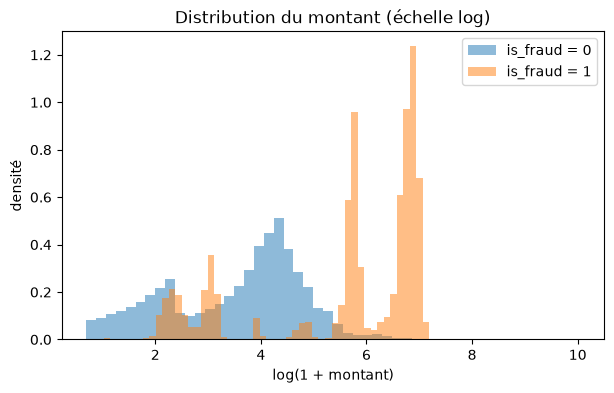

In [119]:
fig, ax = plt.subplots(figsize=(7, 4))
for label, groupe in df.groupby("is_fraud"):
    ax.hist(np.log1p(groupe["amt"]), bins=50, density=True, alpha=0.5, label=f"is_fraud = {label}")
ax.set_xlabel("log(1 + montant)") #au cas où un montant serait nul
ax.set_ylabel("densité")
ax.set_title("Distribution du montant (échelle log)")
ax.legend()
plt.show()

In [120]:
# city_pop
df.groupby("is_fraud")["city_pop"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
0,553574.0,88313.69,300659.35,23.0,741.0,2408.0,19685.0,2906700.0
1,2145.0,64529.32,219207.46,23.0,1131.0,2870.0,12335.0,1577385.0


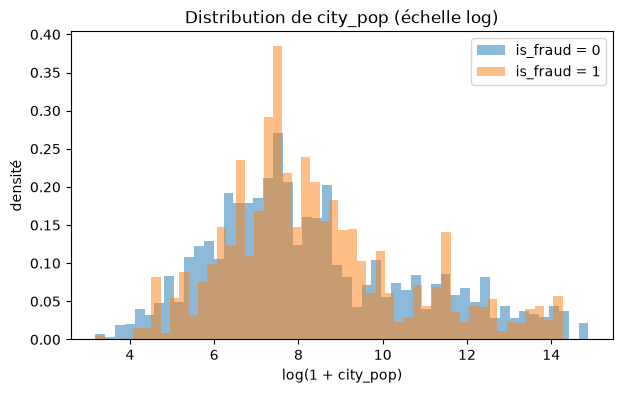

In [121]:
fig, ax = plt.subplots(figsize=(7, 4))
for label, groupe in df.groupby("is_fraud"):
    ax.hist(np.log1p(groupe["city_pop"]), bins=50, density=True, alpha=0.5, label=f"is_fraud = {label}")
ax.set_xlabel("log(1 + city_pop)")
ax.set_ylabel("densité")
ax.set_title("Distribution de city_pop (échelle log)")
ax.legend()
plt.show()

## variables catégorielles

In [122]:
non_numeriques = df.select_dtypes(exclude="number")

nb_modalites = non_numeriques.nunique().sort_values()
print(nb_modalites)

gender                        2
category                     14
state                        50
first                       341
last                        471
job                         478
merchant                    693
city                        849
dob                         910
street                      924
trans_date_trans_time    544760
trans_num                555719
dtype: int64


In [123]:
df["heure"] = pd.to_datetime(df["trans_date_trans_time"]).dt.hour

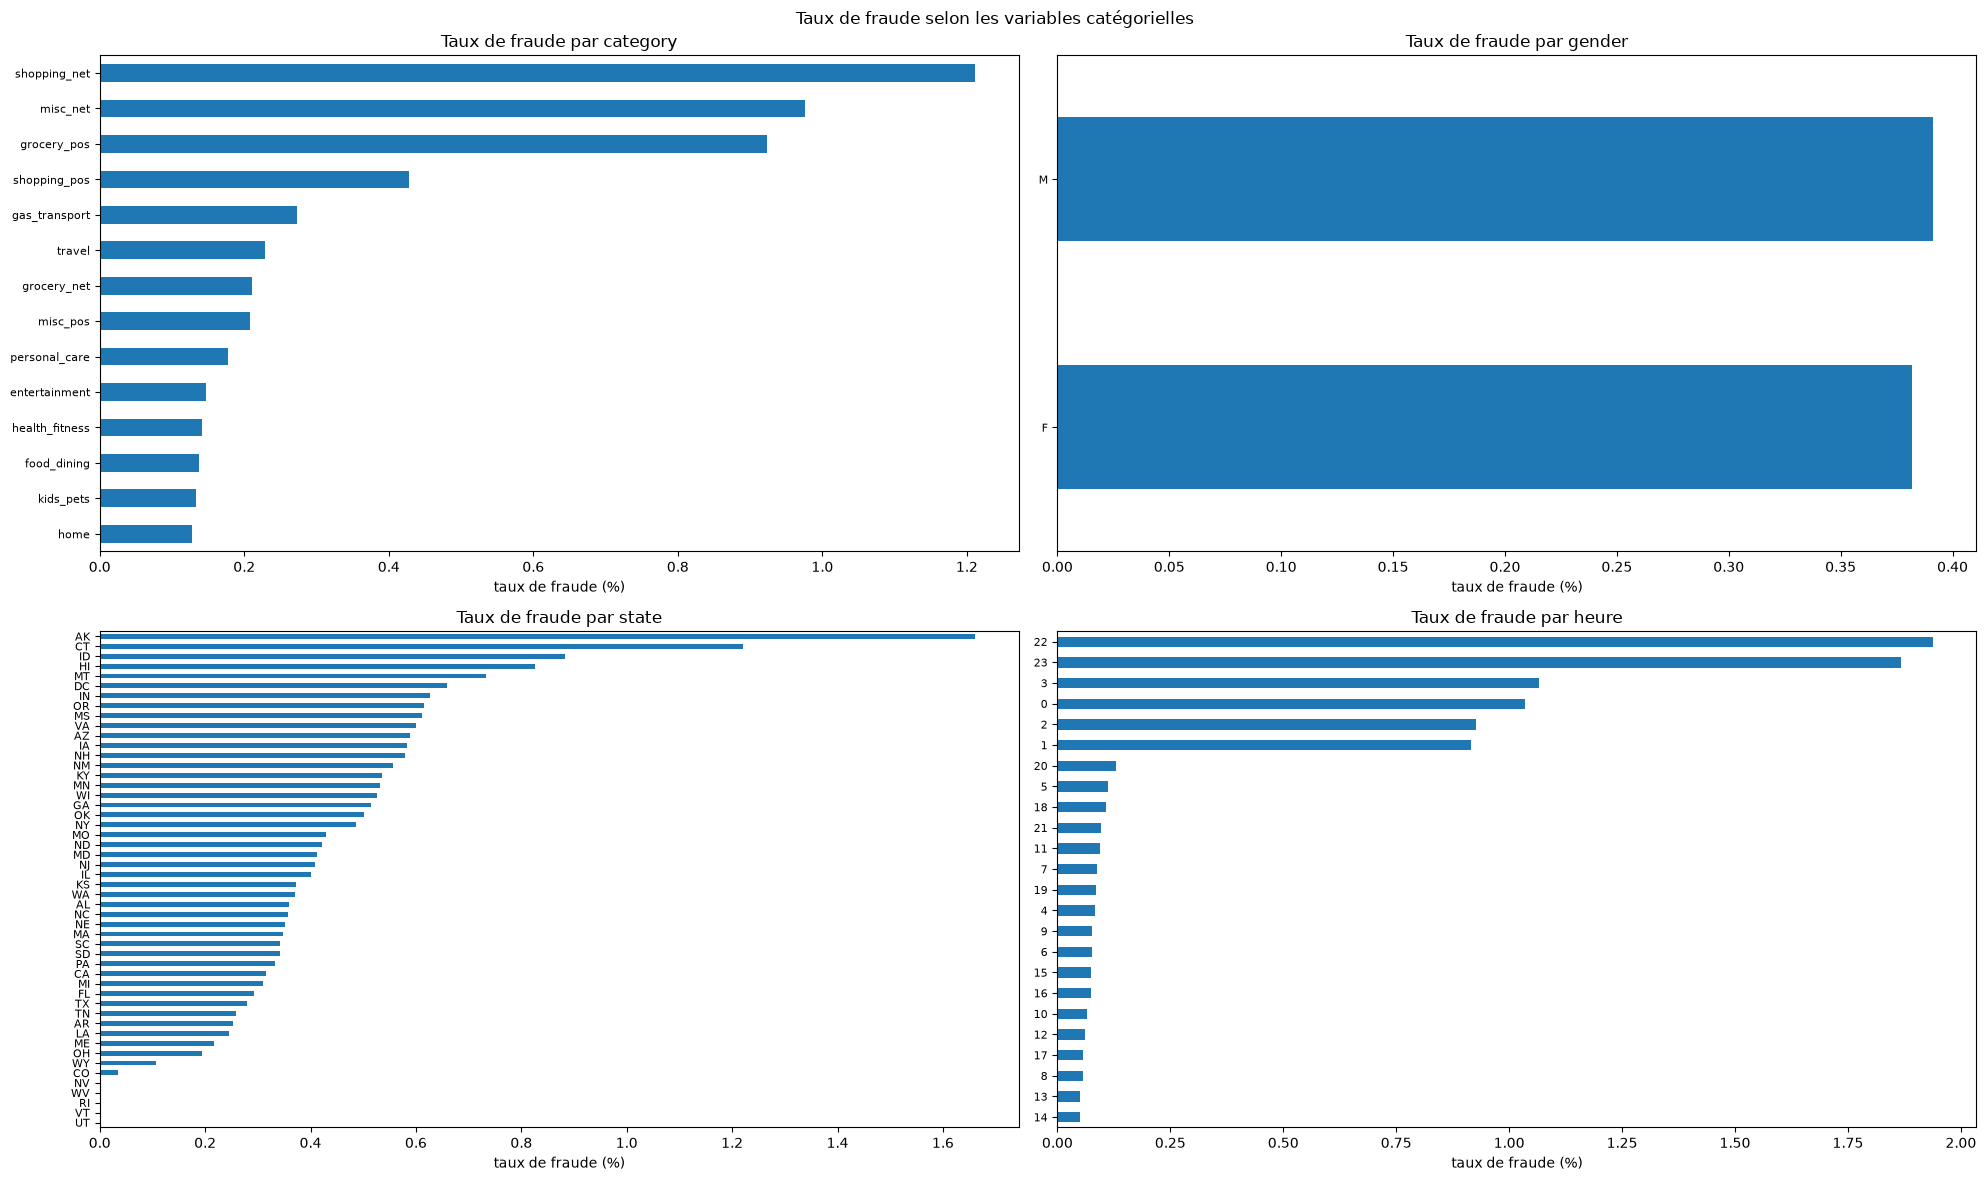

In [124]:
cat_cols = ["category", "gender", "state", "heure"]

fig, axes = plt.subplots(2, 2, figsize=(20, 12))
axes = axes.flatten()
for ax, col in zip(axes, cat_cols):
    taux = df.groupby(col)["is_fraud"].mean() * 100
    taux = taux.sort_values()
    taux.plot(kind="barh", ax=ax)
    ax.set_title(f"Taux de fraude par {col}")
    ax.set_xlabel("taux de fraude (%)")
    ax.set_ylabel("")
    ax.tick_params(axis="y", labelsize=8)
fig.suptitle("Taux de fraude selon les variables catégorielles")
plt.tight_layout()
plt.show()

## 3. Variables du modèle

Au vu de l'EDA, on chosit comme variables explicatives pour un premier modele : le montant, la catégorie, l'état et l'heure.

In [125]:
# donnees API
with open("api_sample.json") as f:
    info_json = json.load(f)
print(f"info du json : {info_json}")
type(info_json)

info du json : {"columns":["cc_num","merchant","category","amt","first","last","gender","street","city","state","zip","lat","long","city_pop","job","dob","trans_num","merch_lat","merch_long","is_fraud","current_time"],"index":[375267],"data":[[213155997615567,"fraud_Koss, Hansen and Lueilwitz","home",84.49,"James","Yoder","M","83359 Lopez Point","Clune","PA",15727,40.5503,-79.3237,168,"Race relations officer","1978-10-04","e46ce7ceec254d56e562ea22220a2bdc",41.166696,-78.509002,0,1792583625552]]}


str

In [126]:
donnees_api = json.loads(info_json)
print(donnees_api)
type(donnees_api)

{'columns': ['cc_num', 'merchant', 'category', 'amt', 'first', 'last', 'gender', 'street', 'city', 'state', 'zip', 'lat', 'long', 'city_pop', 'job', 'dob', 'trans_num', 'merch_lat', 'merch_long', 'is_fraud', 'current_time'], 'index': [375267], 'data': [[213155997615567, 'fraud_Koss, Hansen and Lueilwitz', 'home', 84.49, 'James', 'Yoder', 'M', '83359 Lopez Point', 'Clune', 'PA', 15727, 40.5503, -79.3237, 168, 'Race relations officer', '1978-10-04', 'e46ce7ceec254d56e562ea22220a2bdc', 41.166696, -78.509002, 0, 1792583625552]]}


dict

In [127]:
# Comparaison colonnes API et colonnes dataset
cols_df = set(df.columns)
cols_api = set(donnees_api["columns"])
communes = cols_df & cols_api
print(len(communes), "colonnes communes :")
print(sorted(communes))

# 3. Voir ce qui diffère
print("Seulement dans le dataframe :", sorted(cols_df - cols_api))
print("Seulement dans l'API  :", sorted(cols_api - cols_df))

20 colonnes communes :
['amt', 'category', 'cc_num', 'city', 'city_pop', 'dob', 'first', 'gender', 'is_fraud', 'job', 'last', 'lat', 'long', 'merch_lat', 'merch_long', 'merchant', 'state', 'street', 'trans_num', 'zip']
Seulement dans le dataframe : ['heure', 'trans_date_trans_time', 'unix_time']
Seulement dans l'API  : ['current_time']


In [128]:
#comparaison des champs "trans_date_trans_time" (dataset) et "current_time" (api)
api_df = pd.DataFrame(donnees_api["data"], columns=donnees_api["columns"])

# Heure donnee par l'API
heure_api = pd.to_datetime(api_df.loc[0, "current_time"], unit="ms")

# heure donnee par le dataset (id = trans_num)
numero = api_df.loc[0, "trans_num"]
heure_csv = df.loc[df["trans_num"] == numero, "trans_date_trans_time"].iloc[0]

print(f"heure donnée par l'API : {heure_api}")
print(f"heure dans le CSV      : {heure_csv}")

heure donnée par l'API : 2026-10-21 11:53:45.552000
heure dans le CSV      : 2020-11-14 21:19:54


Les deux champs ne sont pas les mêmes. On ne pourra donc pas utiliser l'heure dans notre modèle (car elle n'est pas fournie par l'API).

On choisit donc d'entraîner le modèle sur les variables explicatives suivantes : montant, catégorie et état (pour un premier modèle simple)

## 4. Séparation train / validation / test

In [129]:
VARIABLES_NUM = ["amt"]
VARIABLES_CAT = ["category", "state"]
VARIABLES = VARIABLES_NUM + VARIABLES_CAT

In [130]:
X = df[VARIABLES]
y = df["is_fraud"]

X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.25, stratify=y_trainval, random_state=RANDOM_STATE
)

for nom, partie in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    print(f"{nom:<11}: {len(partie):>7} paiements, dont {partie.sum():>5} fraudes ({partie.mean()*100:.3f} %)")

train      :  333431 paiements, dont  1287 fraudes (0.386 %)
validation :  111144 paiements, dont   429 fraudes (0.386 %)
test       :  111144 paiements, dont   429 fraudes (0.386 %)


## 5. Entraînement : régression logistique

In [131]:
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), VARIABLES_CAT),
        ("numerical", StandardScaler(), VARIABLES_NUM),
    ]
)

model = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000)),
    ]
)

model.fit(X_train, y_train)
print("Modèle entraîné.")

Modèle entraîné.


Seuil retenu (F1 maximal sur la validation) : 0.025
seuil                          0.025
precision                      0.295
recall                         0.413
f1                             0.344
alertes pour 1000 paiements    5.389
Name: 10, dtype: float64


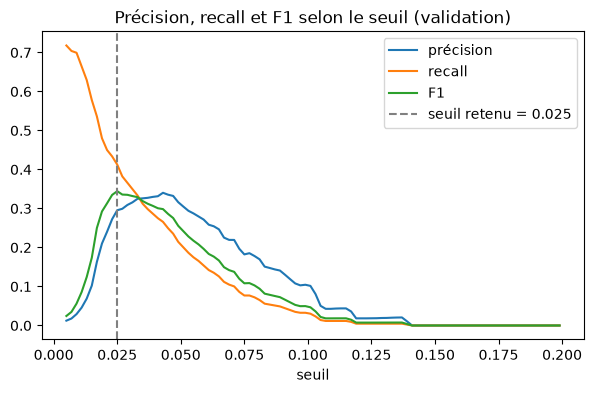

In [132]:
proba_val = model.predict_proba(X_val)[:, 1]

seuils = np.arange(0.005, 0.201, 0.002)
lignes = []
for seuil in seuils:
    pred = (proba_val >= seuil).astype(int)   
    lignes.append({
        "seuil": round(seuil, 3),
        "precision": precision_score(y_val, pred),
        "recall": recall_score(y_val, pred),
        "f1": f1_score(y_val, pred),
        "alertes pour 1000 paiements": pred.mean() * 1000,
    })
resultats = pd.DataFrame(lignes)

meilleur = resultats["f1"].idxmax()            # ligne où le F1 est maximal
THRESHOLD = float(resultats.loc[meilleur, "seuil"])
print(f"Seuil retenu (F1 maximal sur la validation) : {THRESHOLD}")
print(resultats.loc[meilleur].round(3))

plt.figure(figsize=(7, 4))
plt.plot(resultats["seuil"], resultats["precision"], label="précision")
plt.plot(resultats["seuil"], resultats["recall"], label="recall")
plt.plot(resultats["seuil"], resultats["f1"], label="F1")
plt.axvline(THRESHOLD, color="gray", linestyle="--", label=f"seuil retenu = {THRESHOLD}")
plt.xlabel("seuil")
plt.legend()
plt.title("Précision, recall et F1 selon le seuil (validation)")
plt.show()

## 6. Évaluation finale sur le test

Le jeu de test n'a servi ni à entraîner ni à choisir le seuil : c'est notre mesure honnête. On compare le seuil par défaut (0,5) au seuil optimisé.

In [133]:
proba_test = model.predict_proba(X_test)[:, 1]

lignes = []
for nom, seuil in [("seuil par défaut 0.5", 0.5), (f"seuil optimisé {THRESHOLD}", THRESHOLD)]:
    pred = (proba_test >= seuil).astype(int)
    lignes.append({
        "seuil": nom,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred),
        "recall": recall_score(y_test, pred),
        "f1": f1_score(y_test, pred),
    })
    print(nom)
    print("[[vrais négatifs, faux positifs], [faux négatifs, vrais positifs]]")
    print(confusion_matrix(y_test, pred))
    print()

pd.DataFrame(lignes).round(3)

seuil par défaut 0.5
[[vrais négatifs, faux positifs], [faux négatifs, vrais positifs]]
[[110686     29]
 [   429      0]]

seuil optimisé 0.025
[[vrais négatifs, faux positifs], [faux négatifs, vrais positifs]]
[[110307    408]
 [   264    165]]



,seuil,accuracy,precision,recall,f1
0,seuil par défaut 0.5,0.996,0.000,0.000,0.000
1,seuil optimisé 0.025,0.994,0.288,0.385,0.329


## 7. Test sur une vraie transaction de l'API

On vérifie que le modèle accepte de predire à partir d'une transaction renvoyée par l'API. 

In [134]:
proba_api = model.predict_proba(api_df)[0, 1]
print(f"Probabilité de fraude : {proba_api:.4f}")
print(f"Alerte (seuil {THRESHOLD}) : {proba_api >= THRESHOLD}")
print(f"Vraie valeur indiquée par l'API (is_fraud) : {api_df['is_fraud'].iloc[0]}")

Probabilité de fraude : 0.0011
Alerte (seuil 0.025) : False
Vraie valeur indiquée par l'API (is_fraud) : 0


Bilan et suite

- Les classes sont très déséquilibrées (≈ 0,39 % de fraudes)
- Le seuil de décision est choisi sur la validation : c'est un élément du modèle
- Le modèle n'utilise que 3 variables explicatives
- les résultats du modele ne sont pas très probants (à améliorer avec un modele non linéaire)

Prochaine étape (pour la partie ML)
- creer un vrai fichier train.py à partir de ce notebook
- enregistrer le modele et le seuil dans MLFlow